# Storm Stations + Best Track (single case)

**One unified map of a storm's validation stations and its NOAA best track.**

This notebook takes an **explicit hydrograph package path** (the stations) and an **explicit
ATCF track `.dat` path**, then draws both on a single map. Stations are agency-coded
(triangles = observed data, circles = forecast-only) with Agency and Data legends.

Runs locally and on Google Colab. On Colab (or any machine without the files) you can set the
optional download links and the notebook fetches the data first.

**Pipeline:**

```
hydrograph package (stations) + ATCF .dat (track)  ->  one map  ->  outputs/station_track_plots/*.png
```


## 1. Setup --- imports, constants, helpers

`AGENCY_COLORS` is the publication agency palette. The helpers read station metadata from the
hydrograph JSON files and the track from the ATCF `.dat`.

In [12]:
import csv
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import warnings
import cartopy.io
warnings.filterwarnings('ignore', category=cartopy.io.DownloadWarning)

# match agencies

# Publication agency palette33 (matches the station-map script).
AGENCY_COLORS = {
    "NOAA_NOS":    "#CC0000",
    "USGS":        "#009900",
    "USACE":       "#00DDFF",
    "NOAA_RFS":    "#FFBB00",
    "IOC-UNESCO":  "#9900FF",
 #   "TCOON":       "#009688",      #-> NOAA_NOS
 #   "PRSN":        "#E91E63"       #-> NOAA_NOS
}
AGENCY_ORDER = ["USACE", "NOAA_NOS", "USGS", "NOAA_RFS", "IOC-UNESCO"]

ATCF_DATETIME_FORMAT = "%Y%m%d%H"


def load_stations(package_dir: Path) -> pd.DataFrame:
    """Read station metadata from a CERA hydrograph package."""
    hydro_dir = Path(package_dir) / "hydrographs"
    records = []
    for json_file in sorted(hydro_dir.glob("*.json")):
        with open(json_file) as f:
            data = json.load(f)
        # replace TCOON, PRSN with NOAA_NOS
        if data["agency"] in ("TCOON", "PRSN"):
            data["agency"] = "NOAA_NOS"   
        # omit CPRA stations and filter stations that have both observed/forecast arrays
        has_observed_array = isinstance(data.get("observed_data"), list)
        has_forecast_array = isinstance(data.get("forecast_data"), list)
        if not data["agency"].startswith("CPRA") and has_observed_array and has_forecast_array:    
            records.append({
                "station_id": str(data.get("station_id")),
                "station_name": str(data.get("station_name")),
                "agency": str(data.get("agency")),
                "lat": data.get("lat"),
                "lon": data.get("lon"),
                "vertical_datum": str(data.get("vertical_datum"))
        })
    if not records:
        raise ValueError(f"No station JSON files under {hydro_dir}")
    return pd.DataFrame(records)


def load_atcf_track(dat_path: Path) -> list:
    """Return the track as a list of (lat, lon) points from an ATCF DAT file."""
    rows = []
    with open(dat_path, newline="", encoding="utf-8") as f:
        for fields in csv.reader(f):
            fields = [c.strip() for c in fields]
            if len(fields) < 9:
                continue
            try:
                m = re.fullmatch(r"(\d+)([NSEW])", fields[6].upper())
                lat = int(m.group(1)) / 10.0 * (-1 if m.group(2) in ("S", "W") else 1)
                m = re.fullmatch(r"(\d+)([NSEW])", fields[7].upper())
                lon = int(m.group(1)) / 10.0 * (-1 if m.group(2) in ("S", "W") else 1)
                rows.append((lat, lon))
            except (AttributeError, ValueError):
                continue
    return rows

def padded_extent(stations: pd.DataFrame, min_pad: float = 0.75) -> list:
    """Extent covering the stations with padding."""
    lons = list(stations["lon"])
    lats = list(stations["lat"])
    lon_min, lon_max, lat_min, lat_max = min(lons), max(lons), min(lats), max(lats)
    # get the fig width/height in the correct ratio
    lon_span = lon_max - lon_min
    lat_span = lat_max - lat_min
    mean_lat = (lat_min + lat_max) / 2
    width = lon_span * np.cos(np.deg2rad(mean_lat)) # Approximate east-west distance in degrees at the center latitude
    height = lat_span
    # Choose a convenient height in inches
    fig_height = 6.8
    fig_width = fig_height * width / height
    # add padding
    lon_pad = max((lon_max - lon_min) * 0.075, min_pad)
    lat_pad = max((lat_max - lat_min) * 0.075, min_pad)
    return [lon_min - lon_pad, lon_max + lon_pad, lat_min - lat_pad, lat_max + lat_pad, fig_width, fig_height]

def add_base_features(ax) -> None:
    ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#D8DBDE", zorder=0)
    #ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#FFFFFF", zorder=0)
    ax.add_feature(cfeature.LAKES.with_scale("10m"), facecolor="#D8DBDE",
        edgecolor="#A8A8A8", linewidth=0.25, zorder=1)
    ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.22, alpha=0.75, zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#A8A8A8",
        linewidth=0.45, alpha=0.65, zorder=2)
   #ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#CFCFCF",
   #     linewidth=0.30, alpha=0.55, zorder=2)
   # ax.add_feature(cfeature.STATES.with_scale("10m"), edgecolor="#CFCFCF",
   #                linewidth=0.30, alpha=0.55, zorder=2)


def clean_path_part(value: str) -> str:
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(value).strip()).strip("_")

## 2. Paths

`OUTPUT_DIR` is chosen automatically: under `/content` on Colab, next to the notebook locally
(override with `HYDRO_WORKDIR`).

In [13]:
import os
import sys

WORKDIR = Path.cwd().resolve()
DATA_ROOT  = WORKDIR / "data"
OUTPUT_DIR = WORKDIR / "outputs" / "station_track_plots"

print("WORKDIR   :", WORKDIR)
print("DATA_ROOT :", DATA_ROOT)
print("OUTPUT_DIR:", OUTPUT_DIR)


WORKDIR   : D:\Projects\Hindcast_archive\ipynb
DATA_ROOT : D:\Projects\Hindcast_archive\ipynb\data
OUTPUT_DIR: D:\Projects\Hindcast_archive\ipynb\outputs\station_track_plots


## 3. Input --- explicit paths

Edit the cell below. `PACKAGE_DIR` is the CERA hydrograph package (holds `hydrographs/*.json`);
`DAT_PATH` is the ATCF track. The optional URLs are only used when a path is missing
(e.g. on Colab).

In [14]:
# ----------------------------------------------------------------------
# INPUT (explicit paths for the MILTON 2024 case)
# ----------------------------------------------------------------------
#PACKAGE_DIR = (DATA_ROOT / "hydrographs" / "2024" / "MILTON" / "EGOMv20b"
#               / ("CERA_Hydrographs_TimeRange-2024100500-2024101018_"
#                  "Storm-MILTON_Hindcast_BestTrack_ADCIRCMesh-EGOMv20b"))
#DAT_PATH    = DATA_ROOT / "tracks" / "2024_MILTON" / "bal142024.dat"
#TITLE       = "Milton (2024)"

PACKAGE_DIR = (DATA_ROOT / "hydrographs" / "2020" / "LAURA" / "LAERDCv5k"
               / ("CERA_Hydrographs_TimeRange-2020082200-2020082906_Storm-LAURA_Hindcast_BestTrack_ADCIRCMesh-LAERDCv5k"))
DAT_PATH    = DATA_ROOT / "tracks" / "2020_LAURA" / "bal132020.dat"
TITLE       = "Laura (2020)"

DPI           = 300
OUTPUT_FORMAT = "png"

print("PACKAGE_DIR:", PACKAGE_DIR)
print("DAT_PATH   :", DAT_PATH)


PACKAGE_DIR: D:\Projects\Hindcast_archive\ipynb\data\hydrographs\2020\LAURA\LAERDCv5k\CERA_Hydrographs_TimeRange-2020082200-2020082906_Storm-LAURA_Hindcast_BestTrack_ADCIRCMesh-LAERDCv5k
DAT_PATH   : D:\Projects\Hindcast_archive\ipynb\data\tracks\2020_LAURA\bal132020.dat


## 4. Data acquisition

Uses the local package and track when present; otherwise downloads them (hydrographs archive
extracted into `DATA_DIR`, track written to `DAT_PATH`), with optional SHA-256 checks.

In [15]:
# ----------------------------------------------------------------------
# Data acquisition: fetch the single self-contained archive
# (hydrographs + tracks) if it is not already on disk.
#
#   DATA_ROOT/hydrographs/{YEAR}/{STORM}/{MESH}/CERA_Hydrographs_.../hydrographs/*.json
#   DATA_ROOT/tracks/{YEAR}_{STORM}/bal*.dat
#
# Runs on Google Colab and locally. If the data is already present it is skipped.
# ----------------------------------------------------------------------
import hashlib
import ssl
import urllib.request
import zipfile

# Single public download link for per_storm_data.zip (fill in for Colab).
DATA_URL    = "https://cloud.cera.lsu.edu/public.php/dav/files/cq8Tb34b63xjycY/?accept=zip"
# SHA-256 of that archive, verified after download to guard integrity.
DATA_SHA256 = "a090b33f56bab601674e3df092e8cea65604ce9656518b0ae7731e9ed8393657"


def _download(url: str, dest: Path) -> None:
    dest.parent.mkdir(parents=True, exist_ok=True)
    # The CERA host currently serves an expired TLS certificate, so verification
    # is disabled here; the SHA-256 check below is what protects integrity.
    ctx = ssl.create_default_context()
    ctx.check_hostname = False
    ctx.verify_mode = ssl.CERT_NONE
    with urllib.request.urlopen(url, context=ctx) as resp, open(dest, "wb") as fh:
        fh.write(resp.read())


have_data = (DATA_ROOT / "hydrographs").is_dir() and (DATA_ROOT / "tracks").is_dir()
if have_data:
    print("Data already present:", DATA_ROOT)
elif DATA_URL:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_ROOT / "per_storm_data.zip"
    print("Downloading", DATA_URL, "->", zip_path)
    _download(DATA_URL, zip_path)
    if DATA_SHA256:
        digest = hashlib.sha256(zip_path.read_bytes()).hexdigest()
        assert digest == DATA_SHA256, f"checksum mismatch:\n got {digest}\n exp {DATA_SHA256}"
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_ROOT)   # archive top level: hydrographs/ + tracks/
    print("Extracted to", DATA_ROOT)
else:
    raise FileNotFoundError(
        f"Data missing under {DATA_ROOT} and DATA_URL is empty. "
        f"Set DATA_URL to the per_storm_data.zip link."
    )

# Sanity check.
print("Packages found:", len(list((DATA_ROOT / "hydrographs").glob("*/*/*/CERA_Hydrographs_*"))))
print("Track DATs found:", len(list((DATA_ROOT / "tracks").glob("*_*/bal*.dat"))))


Data already present: D:\Projects\Hindcast_archive\ipynb\data
Packages found: 13
Track DATs found: 13


## 5. Load stations and track

In [16]:
stations = load_stations(PACKAGE_DIR)                      
track = load_atcf_track(DAT_PATH)

#print(f"Stations: {len(stations)}  (observed: {int(stations['has_observed'].sum())}, "
#      f"forecast-only: {int((~stations['has_observed']).sum())})")
print("Stations with observed/forecast data:", len(stations))
print("Agencies:", ", ".join(sorted(stations['agency'].unique())))
print("Track points:", len(track))

Stations with observed/forecast data: 128
Agencies: NOAA_NOS, USACE, USGS
Track points: 60


## 6. Render the map

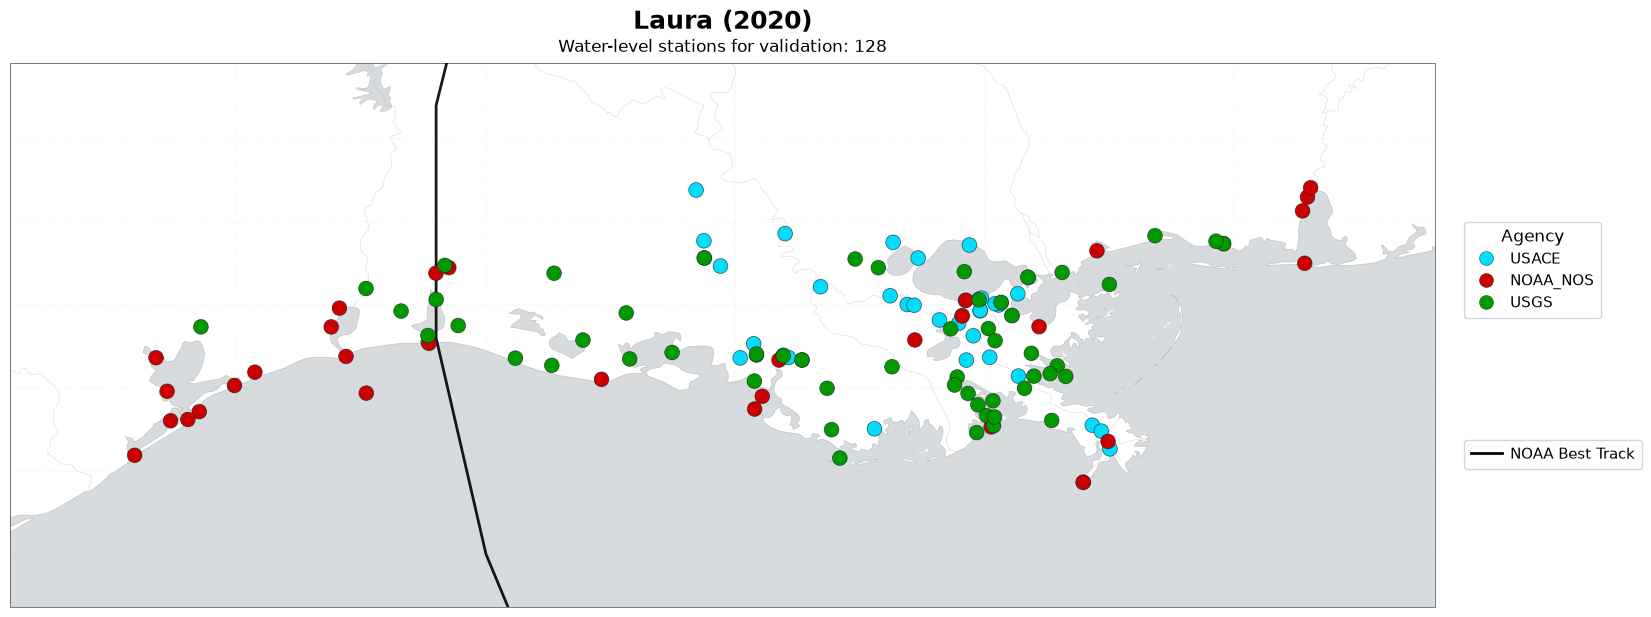

Saved: D:\Projects\Hindcast_archive\ipynb\outputs\station_track_plots\Laura_2020_stations_track.png


In [17]:
#padded_extent
lon_min, lon_max,lat_min, lat_max, fig_width, fig_height = padded_extent(stations)

projection = ccrs.PlateCarree()
fig = plt.figure(figsize=(fig_width, fig_height))
ax = fig.add_axes([0.05, 0.085, 0.70, 0.80], projection=projection)

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_aspect("equal", adjustable="box") #
#fig = plt.figure(figsize=(12.5, 6.8), )
#ax = fig.add_axes([0.05, 0.085, 0.70, 0.80], projection=projection)
#ax.set_extent(extent, crs=projection)
#ax.set_aspect("auto")
add_base_features(ax)

#############################
# track
if track:
   ax.plot([p[1] for p in track], [p[0] for p in track], transform=projection,
       color="black", linewidth=2, zorder=3, alpha=0.9)

ax.gridlines(draw_labels=False, linewidth=0.28, color="#9aa5ad",
    alpha=0.42, linestyle=(0, (2, 3)))

for spine in ax.spines.values():
    spine.set_linewidth(0.55)
    spine.set_edgecolor("#4b5563")
 
# stations   
plotted = [a for a in AGENCY_ORDER if a in set(stations["agency"])]

for agency in plotted: # agency group name
    group = stations[stations["agency"] == agency]
    color = AGENCY_COLORS.get(str(agency))
         
    ax.scatter(group["lon"], group["lat"], transform=projection, s=110, marker="o",
            facecolor=color, edgecolor="#1a1a1a", linewidth=0.3, zorder=5,
            path_effects=[pe.withStroke(linewidth=1.0, foreground="#2f3b43", alpha=0.25)])

legend_style = {"frameon": True, "framealpha": 0.95, "facecolor": "white",
            "edgecolor": "#d0d5da", "borderpad": 0.45, "labelspacing": 0.42,
            "handletextpad": 0.55, "fontsize": 11, "title_fontsize": 12}
#change the legend label for NOAA_RFS
def legend_label(a):
    return "NOAA_NWPS" if a == "NOAA_RFS" else a
    
agency_handles = [
    mlines.Line2D([], [], marker="o", linestyle="None", markersize=10,
            markerfacecolor=AGENCY_COLORS.get(str(a)),
            markeredgecolor="#1a1a1a", markeredgewidth=0.3, label=legend_label(str(a)))
    for a in plotted
]
data_handles = [
    #mlines.Line2D([], [], marker="^", linestyle="None", markersize=9.5,
    #            color="#30343b", label="Observed + forecast"),
    mlines.Line2D([], [], color="black", linewidth=2.0, label="NOAA Best Track"),
]
agency_legend = ax.legend(handles=agency_handles, title="Agency", loc="center left",
                        bbox_to_anchor=(1.015, 0.62), **legend_style)

ax.add_artist(agency_legend)
ax.legend(handles=data_handles, loc="center left",
        bbox_to_anchor=(1.015, 0.28), **legend_style)   #title="Data"

fig.text(0.40, 0.945, TITLE or "Stations + Best Track", ha="center", va="center",
    fontsize=18, fontweight="bold")

fig.text(0.40, 0.908,
    f"Water-level stations for validation: {len(stations)}",
    ha="center", va="center", fontsize=12)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
stem = clean_path_part(TITLE) if len(TITLE)>0 else clean_path_part(PACKAGE_DIR.name)
output_path = OUTPUT_DIR / f"{stem}_stations_track.{OUTPUT_FORMAT}"
fig.savefig(output_path, dpi=DPI, facecolor="white")
plt.show()
plt.close(fig)
print("Saved:", output_path)    


## 7. Done

The map is written to `OUTPUT_DIR`. To plot another case, change `PACKAGE_DIR`, `DAT_PATH`, and
`TITLE` in the **Input** cell and re-run from there.
